# How we found it: exploring the Tangerine data
We started with no theory. We built one profile per customer with the judges' formulas, then plotted everything and followed whatever looked odd. This notebook is that trail, in order: **what we asked, the graph, what we saw, and the question it raised next.**

The trail ends at the findings that drive Guardrails. The tested versions, with confidence intervals and holdout checks, are in `findings/findings_walkthrough.ipynb`.

Run top to bottom (`Run All`). Run it from this `eda/` folder. Every number uses the formulas in `eda_engine/`, so it matches the README formulas.

In [1]:
import sys; sys.path.insert(0, '.')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mtick
from eda_engine.core import load, build_profiles, apply_shock, runway_number, PRESETS
pd.set_option('display.width', 160)
%matplotlib inline

# chart style (reference palette, light)
SURFACE, INK, INK2, MUTED, GRID, BASE = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
BLUE, ORANGE = '#2a78d6', '#eb6834'
plt.rcParams.update({'font.family': ['Helvetica Neue', 'Arial', 'DejaVu Sans'], 'font.size': 11,
    'axes.edgecolor': BASE, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': MUTED,
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'figure.dpi': 110})

def frame(ax, title, subtitle, pct=False, top=None):
    ax.set_title(title, loc='left', fontsize=14, fontweight='bold', color=INK, pad=24)
    ax.text(0, 1.03, subtitle, transform=ax.transAxes, fontsize=10, color=INK2)
    for s in ['top', 'right', 'left']: ax.spines[s].set_visible(False)
    ax.grid(axis='y', color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    ax.tick_params(axis='both', length=0)
    if pct: ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    if top is not None: ax.set_ylim(0, top)

def labels(ax, bars, fmt):
    for b in bars:
        ax.text(b.get_x()+b.get_width()/2, b.get_height(), fmt(b.get_height()), ha='center', va='bottom',
                fontsize=10, color=INK, fontweight='bold')

def bars(ax, names, values, color=BLUE, width=0.55):
    return ax.bar(names, values, color=color, width=width, edgecolor=SURFACE, linewidth=2)

## Step 1. One row per customer
4,500 accounts of monthly money in and out. We turned each into the judges' figures: income (I), spending (S), savings (B), bills (H), loan payment (P), and runway after a job loss on EI.

In [2]:
D = '../data/data'
ms, loans = load(D)
prof = build_profiles(ms, loans)
clients = pd.read_csv(f'{D}/clients.csv', parse_dates=['birth_date'])
disp = pd.read_csv(f'{D}/dispositions.csv'); districts = pd.read_csv(f'{D}/districts.csv')
cards = pd.read_csv(f'{D}/cards.csv')

owner = disp[disp.type == 'owner'].merge(clients, on='client_id')
owner['age'] = ((pd.Timestamp('2025-12-31') - owner.birth_date).dt.days / 365.25).astype(int)
x = prof.join(owner.set_index('account_id')[['gender', 'age', 'district_id']])
x = x.reset_index().merge(districts[['district_id','region','average_salary','unemployment_rate_2023']], on='district_id', how='left').set_index('account_id')
x['card'] = disp.merge(cards, on='disposition_id').groupby('account_id').card_type.first().reindex(x.index).fillna('none')
x['loan'] = loans.set_index('account_id').status.reindex(x.index).fillna('none')
g = ms.groupby('account_id')
x['pension_share'] = (g.pension_in.sum() / g.money_in.sum()).reindex(x.index)
x['retiree'] = x.pension_share > 0.5
x['savings_rate'] = (x.I_income - x.S_spending) / x.I_income.where(x.I_income > 0)
x['buffer_months'] = x.B_buffer / x.S_spending
x['ei_runway'] = [runway_number(apply_shock(p, PRESETS['job_loss_ei'])['runway_after']) for _, p in prof.iterrows()]
x['survives_ei_6m'] = x.ei_runway >= 6
print(f'{len(x):,} accounts | {len(ms):,} account-months | {len(loans)} loans | retirees: {x.retiree.sum()}')
x[['I_income','S_spending','B_buffer','base_runway','ei_runway','age','loan']].head()

4,500 accounts | 185,326 account-months | 682 loans | retirees: 740


,I_income,S_spending,B_buffer,base_runway,ei_runway,age,loan
account_id,,,,,,,
20111,6339.390,8599.605,17611.863333,7.8,3.4,59,D
20133,24194.040,20476.190,30197.925000,no shortfall (120+),4.2,57,none
20134,7958.000,8060.520,16599.456667,120,4.5,33,C
20143,30870.660,34579.700,39545.621667,10.7,2.2,30,A
20160,13392.435,13564.930,31662.453333,120,5.1,50,none


## Step 2. First look: who are these people?
**We asked:** before any shock, what do age, income and savings look like?

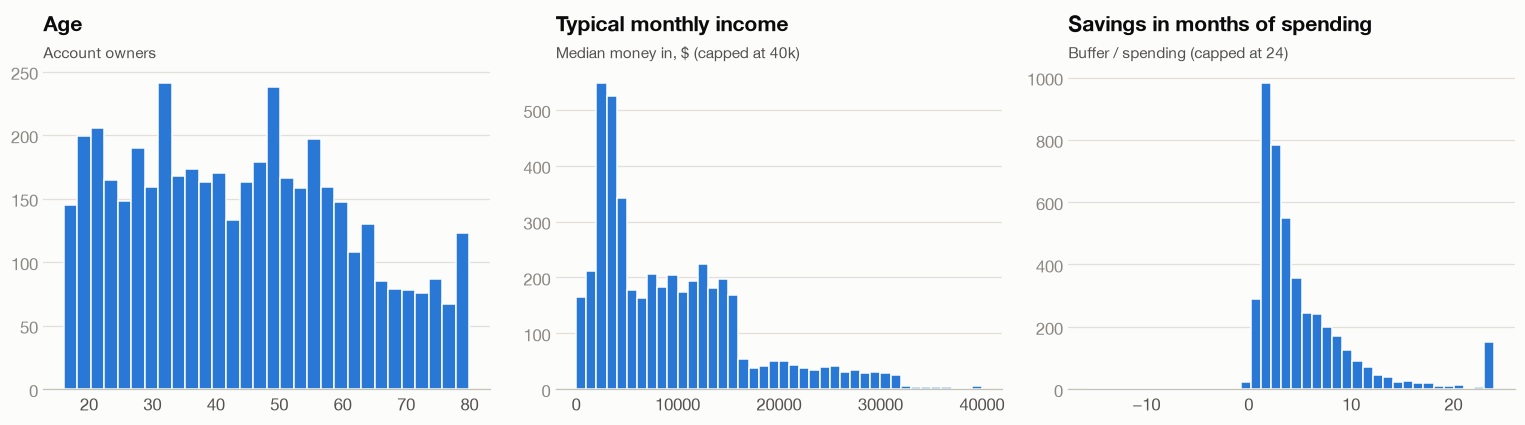

median income $7568 | median spending $7389 | median buffer $22325
spend more than they earn in a typical month: 26.2%


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(x.age, bins=30, color=BLUE, edgecolor=SURFACE); frame(axes[0], 'Age', 'Account owners')
axes[1].hist(x.I_income.clip(upper=40000), bins=40, color=BLUE, edgecolor=SURFACE); frame(axes[1], 'Typical monthly income', 'Median money in, $ (capped at 40k)')
axes[2].hist(x.buffer_months.clip(upper=24), bins=40, color=BLUE, edgecolor=SURFACE); frame(axes[2], 'Savings in months of spending', 'Buffer / spending (capped at 24)')
plt.tight_layout(); plt.show()
print('median income $%.0f | median spending $%.0f | median buffer $%.0f' % (x.I_income.median(), x.S_spending.median(), x.B_buffer.median()))
print('spend more than they earn in a typical month: %.1f%%' % (100*(x.savings_rate < 0).mean()))

**What we saw:** income and savings are both long-tailed, and savings measured in *months of spending* are thin for many people. That made us ask how many would actually make it through a shock.

## Step 2b. Our first round of plots
**We asked:** with no theory yet, what does the money actually do? We plotted five things and kept the ones that looked odd.

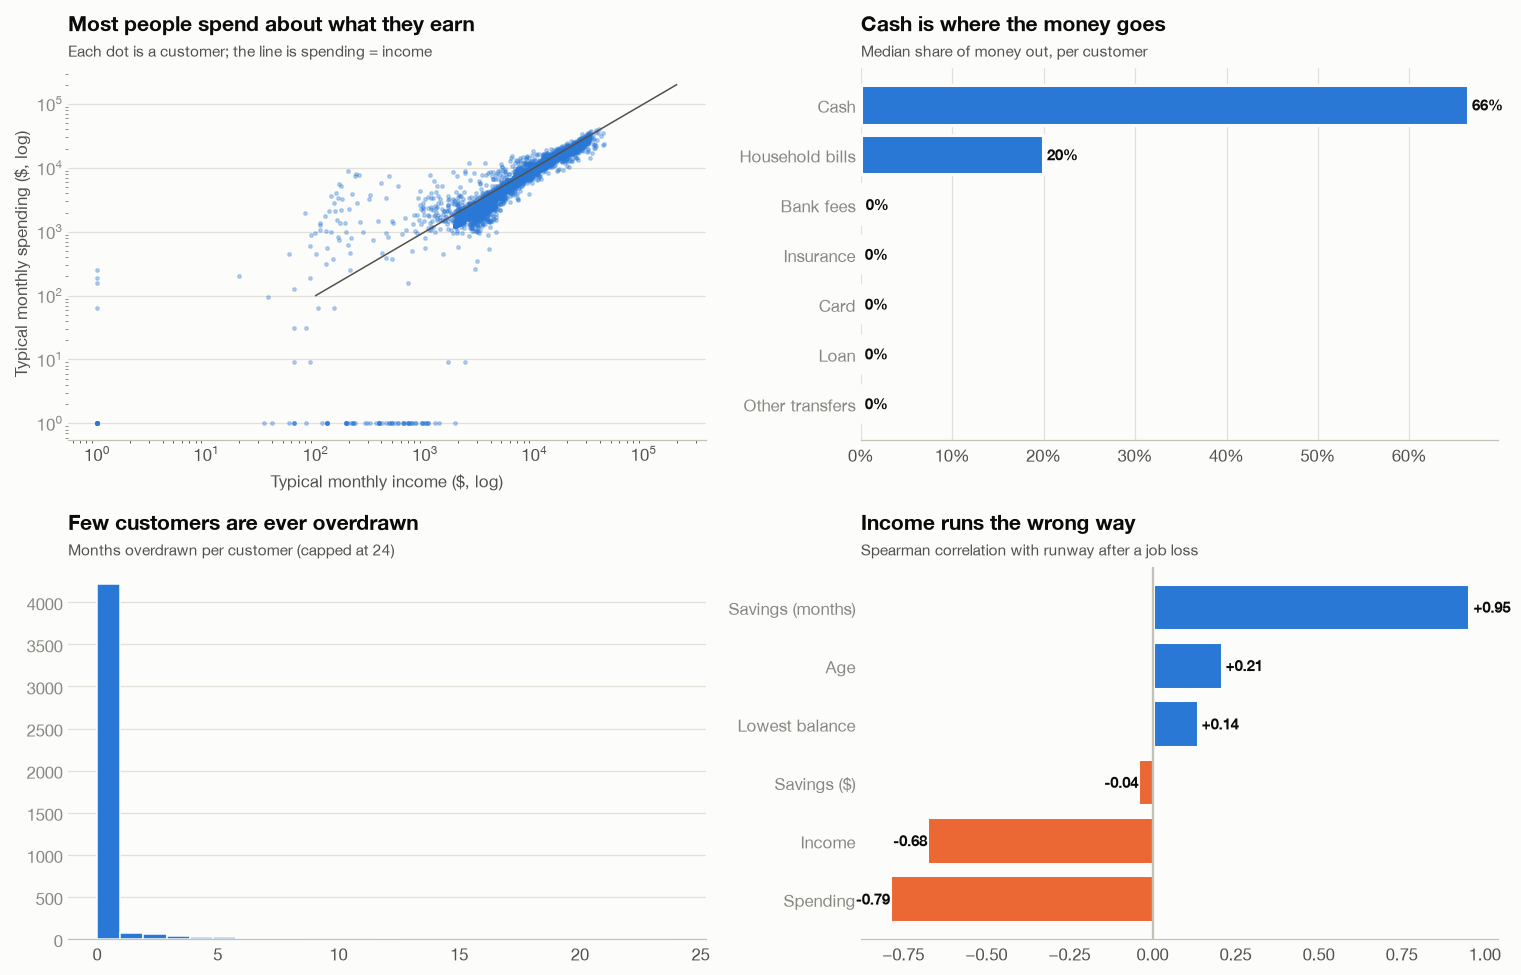

overdrawn at least once: 6% of customers
correlations: {'Spending': -0.79, 'Income': -0.68, 'Savings ($)': -0.04, 'Lowest balance': 0.14, 'Age': 0.21, 'Savings (months)': 0.95}


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
# a. money in vs money out
ax = axes[0, 0]
ax.scatter(x.I_income.clip(lower=1), x.S_spending.clip(lower=1), s=5, alpha=0.3, color=BLUE)
lim = [100, 2e5]; ax.plot(lim, lim, color=INK2, linewidth=1); ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Typical monthly income ($, log)'); ax.set_ylabel('Typical monthly spending ($, log)')
frame(ax, 'Most people spend about what they earn', 'Each dot is a customer; the line is spending = income')
# b. where the money goes
ax = axes[0, 1]
cats = ['cash_withdrawals_genuine', 'transfers_out_other', 'household_bills', 'loan_payments', 'card_withdrawals', 'insurance', 'bank_fees']
share = (ms.groupby('account_id')[cats].sum().div(ms.groupby('account_id').money_out.sum(), axis=0)).median().sort_values()
nice = {'cash_withdrawals_genuine': 'Cash', 'transfers_out_other': 'Other transfers', 'household_bills': 'Household bills', 'loan_payments': 'Loan', 'card_withdrawals': 'Card', 'insurance': 'Insurance', 'bank_fees': 'Bank fees'}
ax.barh([nice[c] for c in share.index], share.values, color=BLUE, edgecolor=SURFACE, linewidth=2)
for i, v in enumerate(share.values): ax.text(v, i, f' {v:.0%}', va='center', fontsize=10, color=INK, fontweight='bold')
frame(ax, 'Cash is where the money goes', 'Median share of money out, per customer'); ax.grid(axis='x', color=GRID); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
# c. how often people are overdrawn
ax = axes[1, 0]
od = (ms.days_below_zero > 0).groupby(ms.account_id).sum()
ax.hist(od.clip(upper=24), bins=25, color=BLUE, edgecolor=SURFACE)
frame(ax, 'Few customers are ever overdrawn', 'Months overdrawn per customer (capped at 24)')
# d. which simple signal tracks runway after a job loss?
ax = axes[1, 1]
sig = pd.DataFrame({'Income': x.I_income, 'Spending': x.S_spending, 'Savings ($)': x.B_buffer, 'Savings (months)': x.buffer_months,
                    'Lowest balance': ms.groupby('account_id').min_balance.min().reindex(x.index), 'Age': x.age})
rho = sig.apply(lambda c: c.corr(x.ei_runway, method='spearman')).sort_values()
ax.barh(rho.index, rho.values, color=[ORANGE if v < 0 else BLUE for v in rho.values], edgecolor=SURFACE, linewidth=2)
for i, v in enumerate(rho.values): ax.text(v, i, f' {v:+.2f}', va='center', ha='left' if v >= 0 else 'right', fontsize=10, color=INK, fontweight='bold')
ax.axvline(0, color=BASE); frame(ax, 'Income runs the wrong way', 'Spearman correlation with runway after a job loss'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
print('overdrawn at least once: %.0f%% of customers' % (100 * (od > 0).mean()))
print('correlations:', rho.round(2).to_dict())

**What we saw:**
- Most people spend close to what they earn, so a drop in income turns into a gap almost at once.
- For the typical customer, about two thirds of money out is cash and a fifth is household bills. Cash is the one big flexible line, which is why we later asked what people cut in a crash.
- Only about 6% of customers were ever overdrawn, so overdrafts are a rare outcome that we would have to predict early.
- Runway after a job loss tracks *savings in months* almost one for one (that is close to how runway is defined). The surprise was income: it runs the **wrong way** (−0.68), because spending rises with it (−0.79). That one bar set up Steps 3 to 5.

## Step 2c. Every variable against every other
**We asked:** which things move together? We took twelve per-customer measures and correlated each pair (Spearman, so a few very large accounts can't dominate).

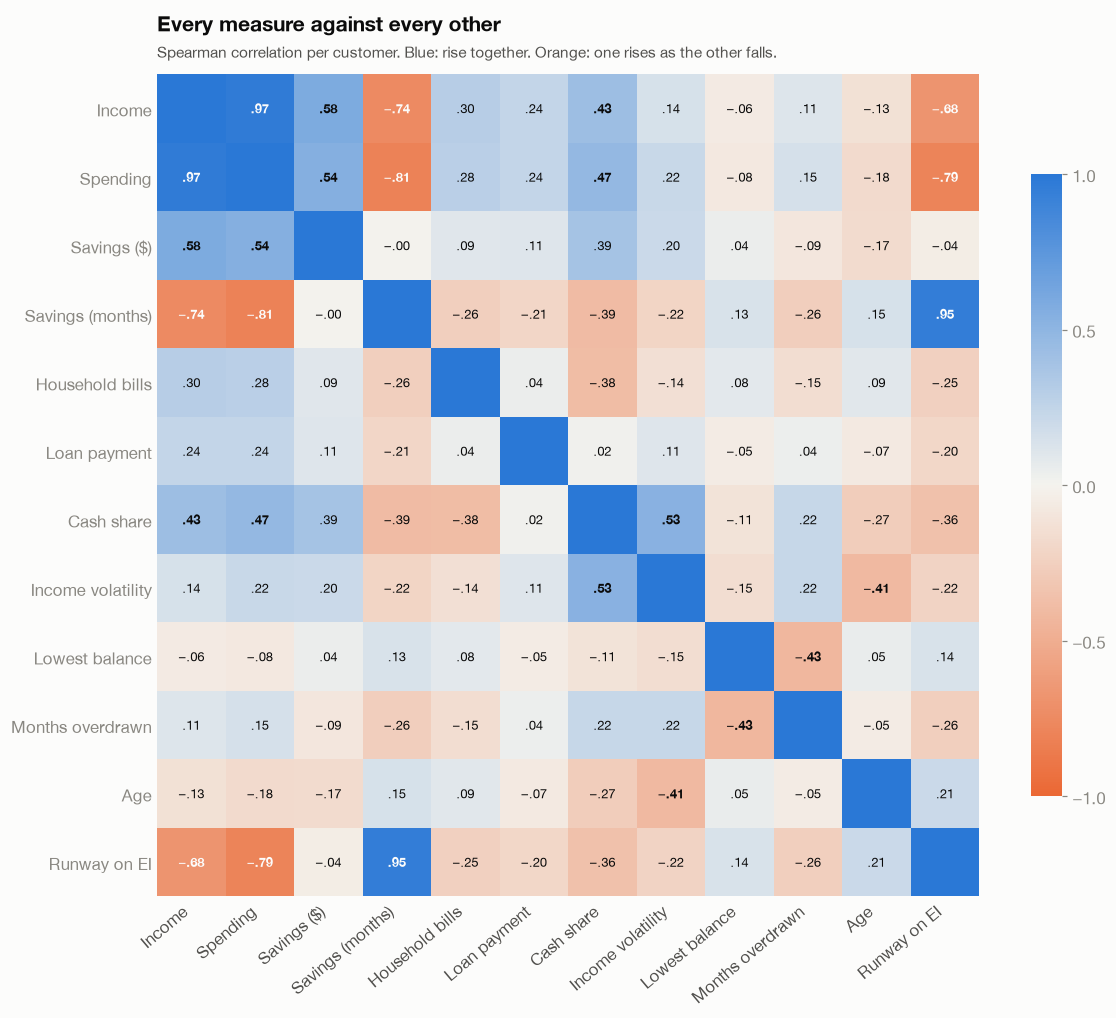

strongest pairs:
Income            Spending            0.97
Savings (months)  Runway on EI        0.95
Spending          Savings (months)   -0.81
                  Runway on EI       -0.79
Income            Savings (months)   -0.74
                  Runway on EI       -0.68
                  Savings ($)         0.58
Spending          Savings ($)         0.54
runway on EI vs each:
Spending            -0.79
Income              -0.68
Cash share          -0.36
Months overdrawn    -0.26
Household bills     -0.25
Income volatility   -0.22
Loan payment        -0.20
Savings ($)         -0.04
Lowest balance       0.14
Age                  0.21
Savings (months)     0.95


In [5]:
from matplotlib.colors import LinearSegmentedColormap
g = ms.groupby('account_id')
v = pd.DataFrame({
    'Income': x.I_income, 'Spending': x.S_spending, 'Savings ($)': x.B_buffer, 'Savings (months)': x.buffer_months,
    'Household bills': x.H_bills if 'H_bills' in x else g.household_bills.median().reindex(x.index),
    'Loan payment': g.loan_payments.median().reindex(x.index),
    'Cash share': (g.cash_withdrawals_genuine.sum() / g.money_out.sum()).reindex(x.index),
    'Income volatility': (g.money_in.std() / g.money_in.mean()).reindex(x.index),
    'Lowest balance': g.min_balance.min().reindex(x.index),
    'Months overdrawn': (ms.days_below_zero > 0).groupby(ms.account_id).sum().reindex(x.index),
    'Age': x.age, 'Runway on EI': x.ei_runway})
C = v.corr(method='spearman')
cmap = LinearSegmentedColormap.from_list('div', [ORANGE, '#f4f3ee', BLUE])
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(C.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(C)), C.columns, rotation=40, ha='right'); ax.set_yticks(range(len(C)), C.index)
for i in range(len(C)):
    for j in range(len(C)):
        if i != j: ax.text(j, i, f'{C.iat[i, j]:+.2f}'.replace('+0.', '.').replace('-0.', '−.'), ha='center', va='center', fontsize=8.5,
                           color=INK if abs(C.iat[i, j]) < 0.6 else SURFACE, fontweight='bold' if abs(C.iat[i, j]) >= 0.4 else 'normal')
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(length=0)
ax.set_title('Every measure against every other', loc='left', fontsize=14, fontweight='bold', color=INK, pad=28)
ax.text(0, 1.02, 'Spearman correlation per customer. Blue: rise together. Orange: one rises as the other falls.', transform=ax.transAxes, fontsize=10, color=INK2)
cb = fig.colorbar(im, ax=ax, shrink=0.7, ticks=[-1, -0.5, 0, 0.5, 1]); cb.outline.set_visible(False)
plt.tight_layout(); plt.show()
pairs = C.where(np.triu(np.ones(C.shape, bool), 1)).stack().sort_values(key=abs, ascending=False)
print('strongest pairs:'); print(pairs.head(8).round(2).to_string())
print('runway on EI vs each:'); print(C['Runway on EI'].drop('Runway on EI').sort_values().round(2).to_string())

**What we saw:** Income and spending move almost in lockstep (.97), so earning more mostly means spending more. Richer customers hold more savings in dollars (.58) but *fewer months* of savings (−.74), and months are what runway is made of (.95). Dollars of savings barely relate to runway at all (−.04). Among the smaller signals, a high cash share goes with unsteady income (.53), and the lowest balance goes with months overdrawn (−.43). Those pointed us at cash, steadiness and the worst day.

## Step 3. Hit everyone with the brief's shocks
**We asked:** with the README formulas, how many run out of savings within 6 months under each shock?

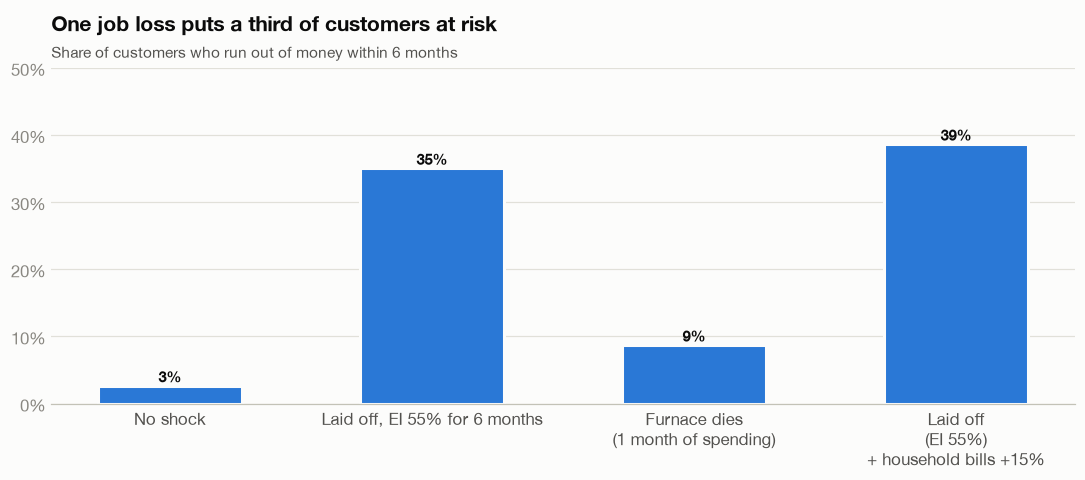

In [6]:
rows = []
for key, shock in PRESETS.items():
    r = [runway_number(apply_shock(p, shock)['runway_after']) for _, p in prof.iterrows()]
    rows.append((shock.label, np.mean(np.array(r) < 6)))
base = [runway_number(v) for v in prof.base_runway]
rows.insert(0, ('No shock', np.mean(np.array(base) < 6)))
s = pd.DataFrame(rows, columns=['scenario', 'out_within_6m']).set_index('scenario')
fig, ax = plt.subplots(figsize=(10, 4.5))
b = bars(ax, [t.replace(' (', '\n(').replace(' + ', '\n+ ') for t in s.index], s.out_within_6m)
labels(ax, b, lambda v: f'{v:.0%}')
frame(ax, 'One job loss puts a third of customers at risk', 'Share of customers who run out of money within 6 months', pct=True, top=0.5)
plt.tight_layout(); plt.show()

**What we saw:** a single job loss on EI puts about a third of customers out of money within 6 months. Our first guess was that these would be the low earners. So we checked.

## Step 4. Surprise: higher earners survive *less* often
**We asked:** does survival rise with income? Working customers only (retirees removed, because a job loss can't cut a pension).

,median_income,buffer_months,savings_rate,survives
q,,,,
Lowest 25%,2084.77,8.77,0.22,0.92
2nd,7096.36,3.29,0.05,0.62
3rd,11992.03,2.50,0.02,0.49
Highest 25%,19704.87,1.81,0.05,0.30


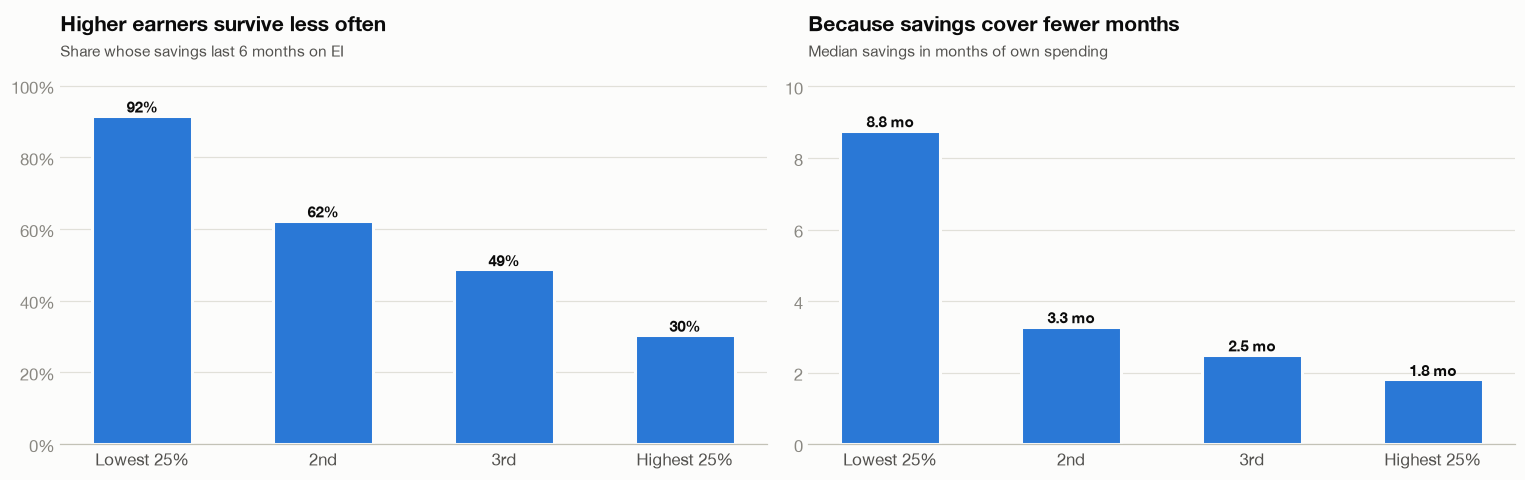

Spearman corr, income vs EI runway (workers): -0.60


In [7]:
w = x[~x.retiree].copy()
w['q'] = pd.qcut(w.I_income, 4, labels=['Lowest 25%', '2nd', '3rd', 'Highest 25%'])
t = w.groupby('q', observed=True).agg(median_income=('I_income','median'), buffer_months=('buffer_months','median'),
                                     savings_rate=('savings_rate','median'), survives=('survives_ei_6m','mean'))
display(t.round(2))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
labels(axes[0], bars(axes[0], t.index.astype(str), t.survives), lambda v: f'{v:.0%}')
frame(axes[0], 'Higher earners survive less often', 'Share whose savings last 6 months on EI', pct=True, top=1.05)
labels(axes[1], bars(axes[1], t.index.astype(str), t.buffer_months), lambda v: f'{v:.1f} mo')
frame(axes[1], 'Because savings cover fewer months', 'Median savings in months of own spending', top=t.buffer_months.max()*1.2)
plt.tight_layout(); plt.show()
print('Spearman corr, income vs EI runway (workers): %.2f' % w[['I_income','ei_runway']].corr(method='spearman').iloc[0,1])

**What we saw:** the opposite of our guess. Higher earners spend more, so the same savings cover fewer months. Before believing it, we needed to rule out a data quirk.

## Step 5. Is it real?
**Check before claiming:** do the lowest-income accounts look like *real* low earners, or like accounts where most money arrives elsewhere? A side account would show small income *and* small spending.

Lowest 25%: median income $2085, median spending $1636, median buffer $14179
share with buffer > 12 months of spending: 29%


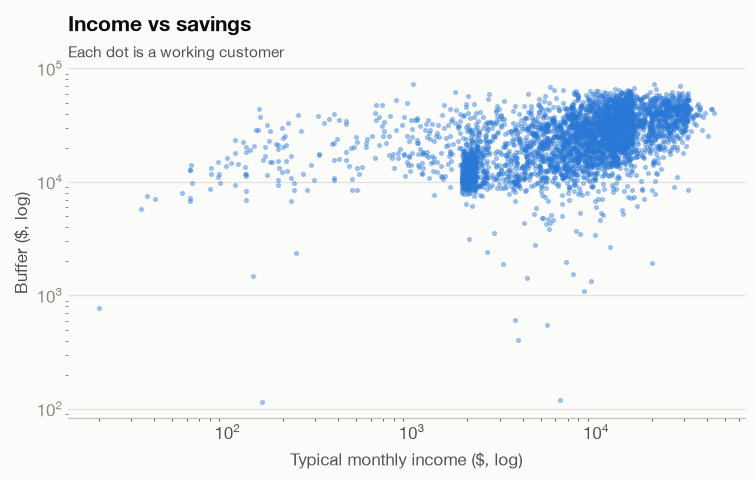

In [8]:
q1 = w[w.q == 'Lowest 25%']
print('Lowest 25%%: median income $%.0f, median spending $%.0f, median buffer $%.0f' % (q1.I_income.median(), q1.S_spending.median(), q1.B_buffer.median()))
print('share with buffer > 12 months of spending: %.0f%%' % (100*(q1.buffer_months > 12).mean()))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(w.I_income, w.B_buffer, s=6, alpha=0.35, color=BLUE)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('Typical monthly income ($, log)'); ax.set_ylabel('Buffer ($, log)')
frame(ax, 'Income vs savings', 'Each dot is a working customer')
plt.tight_layout(); plt.show()

**What we saw:** the low earners look like real low earners, not side accounts. The pattern held. If income level doesn't tell you who gets into trouble, what does? Loans gave us a real outcome to test against.

## Step 6. What predicts loan default?
**We asked:** which signals, measured *before* a loan started, separate the loans that defaulted? 615 loans with at least 6 months of history; signals measured in the 12 months **before** the loan.

In [9]:
from sklearn.metrics import roc_auc_score
ms['m'] = pd.to_datetime(ms.month)
feat = []
for _, l in loans.iterrows():
    h = ms[(ms.account_id == l.account_id) & (ms.m < pd.Timestamp(l.loan_start).to_period('M').to_timestamp())].tail(12)
    if len(h) < 6: continue
    feat.append({'defaulted': l.defaulted, 'income': h.money_in.median(),
                 'income_volatility': h.money_in.std() / max(h.money_in.mean(), 1),
                 'worst_day_balance': h.min_balance.min(),
                 'buffer_months': h.avg_daily_balance.tail(6).mean() / max(h.money_out.median(), 1)})
L = pd.DataFrame(feat)
auc = {c: max(roc_auc_score(L.defaulted, L[c]), 1 - roc_auc_score(L.defaulted, L[c])) for c in ['worst_day_balance','income_volatility','buffer_months','income']}
print(f'{len(L)} loans, {int(L.defaulted.sum())} defaults')
pd.Series(auc, name='AUC (0.5 = coin flip)').round(3).to_frame()

615 loans, 65 defaults


,AUC (0.5 = coin flip)
worst_day_balance,0.823
income_volatility,0.700
buffer_months,0.655
income,0.557


**What we saw:** the lowest balance of the year and how unsteady income is both beat income level. We split the loans to see it plainly.

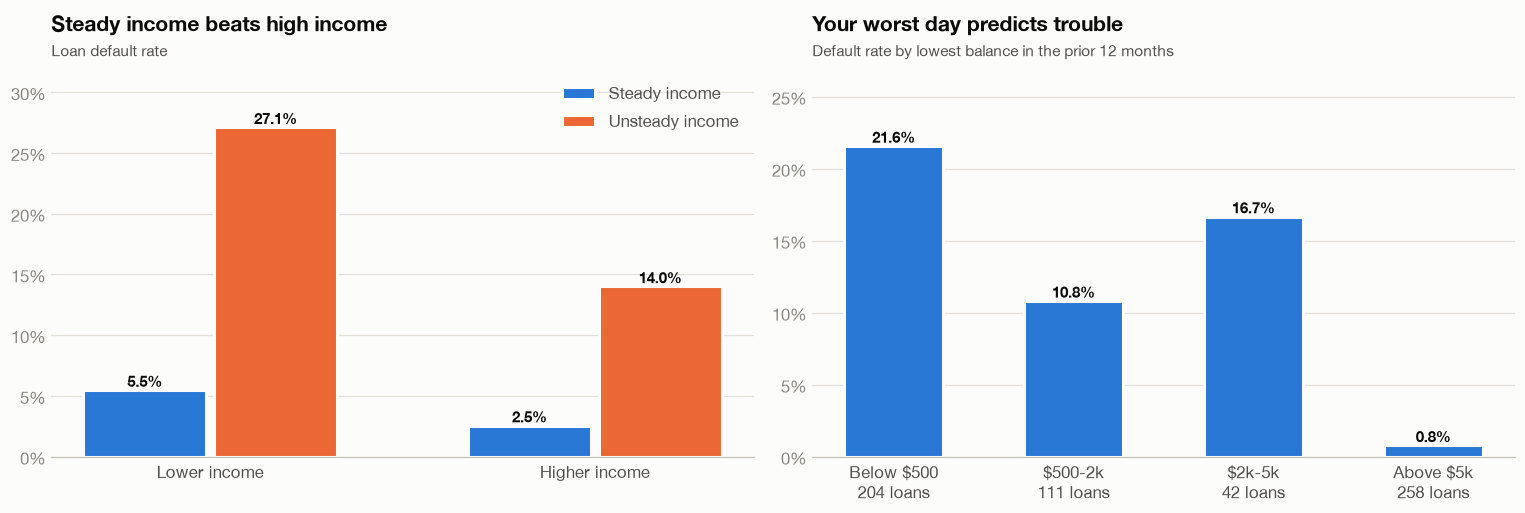

In [10]:
L['level'] = np.where(L.income > L.income.median(), 'Higher income', 'Lower income')
L['steady'] = L.income_volatility < 0.5
t = L.groupby(['level','steady']).defaulted.mean().unstack().loc[['Lower income','Higher income']]
L['worst'] = pd.cut(L.worst_day_balance, [-1e9, 500, 2000, 5000, 1e9], labels=['Below $500','$500-2k','$2k-5k','Above $5k'])
d = L.groupby('worst', observed=True).defaulted.agg(['mean','size'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
pos = np.arange(2); wd = 0.32
labels(axes[0], axes[0].bar(pos-wd/2-0.01, t[True], wd, color=BLUE, label='Steady income', edgecolor=SURFACE, linewidth=2), lambda v: f'{v:.1%}')
labels(axes[0], axes[0].bar(pos+wd/2+0.01, t[False], wd, color=ORANGE, label='Unsteady income', edgecolor=SURFACE, linewidth=2), lambda v: f'{v:.1%}')
axes[0].set_xticks(pos, t.index); axes[0].legend(frameon=False, labelcolor=INK2)
frame(axes[0], 'Steady income beats high income', 'Loan default rate', pct=True, top=0.32)
labels(axes[1], bars(axes[1], [f'{k}\n{n} loans' for k, n in zip(d.index.astype(str), d['size'])], d['mean']), lambda v: f'{v:.1%}')
frame(axes[1], 'Your worst day predicts trouble', 'Default rate by lowest balance in the prior 12 months', pct=True, top=0.27)
plt.tight_layout(); plt.show()

**What we saw:** steady income matters more than high income, and a dip below $500 marks the loans that went bad. Those two signals became guardrails: a low-balance alert, and an early talk with the lender.

## A lead we dropped: "income crashes cluster in January"
**Why we believed it.** To study real shocks, we found every account whose income fell to half of normal or less for 3 months in a row (569 accounts) and took the *first* crash for each. Almost one in five of those started in January, more than twice the share of any other month. January is also when spending spikes, so the story fit.

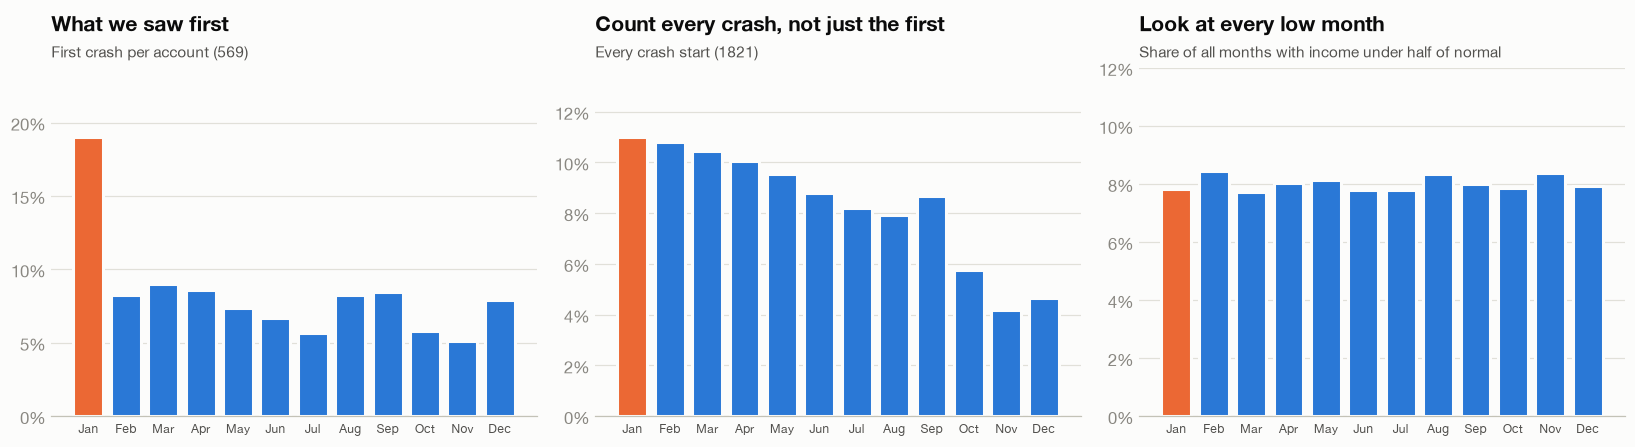

January share: first crash 19% | every crash start 11% | all low months 7.8% (other months 7.7%-8.5%)
January median spending $11518 vs February $4392 (this part is real)


In [11]:
names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
first, every = [], []
for acc, g in ms.sort_values(['account_id', 'month']).groupby('account_id'):
    mi, mo, got = g.money_in.values, g.month.values, False
    for i in range(12, len(g) - 3):
        base = np.median(mi[i-12:i])
        if base > 0 and (mi[i:i+3] <= 0.5 * base).all():
            every.append(int(mo[i][5:]))
            if not got: first.append(int(mo[i][5:])); got = True
ms['mon'] = ms.month.str[5:].astype(int)
low = ms.money_in < 0.5 * ms.groupby('account_id').money_in.transform('median')
views = [(pd.Series(first).value_counts(normalize=True).reindex(range(1, 13), fill_value=0), f'First crash per account ({len(first)})', 'What we saw first'),
         (pd.Series(every).value_counts(normalize=True).reindex(range(1, 13), fill_value=0), f'Every crash start ({len(every)})', 'Count every crash, not just the first'),
         (low.groupby(ms.mon).mean(), 'Share of all months with income under half of normal', 'Look at every low month')]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=False)
for ax, (v, sub, title) in zip(axes, views):
    ax.bar(names, v.values, color=[ORANGE if k == 0 else BLUE for k in range(12)], edgecolor=SURFACE, linewidth=2)
    frame(ax, title, sub, pct=True, top=max(v.max() * 1.25, 0.12)); ax.tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.show()
print('January share: first crash %.0f%% | every crash start %.0f%% | all low months %.1f%% (other months %.1f%%-%.1f%%)' % (
    100 * views[0][0][1], 100 * views[1][0][1], 100 * views[2][0][1], 100 * views[2][0].drop(1).min(), 100 * views[2][0].drop(1).max()))
sea = ms.groupby('mon').money_out.median()
print('January median spending $%.0f vs February $%.0f (this part is real)' % (sea[1], sea[2]))

**Why we dropped it.** The spike came from *how we picked* crashes, not from January. Keeping only the first crash per account favours whichever month a long slump happens to start in. Count every crash and January is level with February; count every low-income month and each calendar month has about the same share. So crashes do not cluster in January, and nothing in Guardrails uses that claim. The January *spending* spike is real and stays in the data story.

**Lesson we kept:** before believing a pattern, change how it is counted. If it moves, it was the counting.

## Step 7. Scan every other segment
**We asked:** what else moves survival? We cut the EI result by age, retirement, loans, cards, district and gender.

In [12]:
def seg(col, bins=None, lab=None):
    k = pd.cut(x[col], bins, labels=lab) if bins else x[col]
    return x.groupby(k, observed=True).agg(n=('ei_runway','size'), survives_EI_6m=('survives_ei_6m','mean'), median_EI_runway=('ei_runway','median')).round(2)
for name, args in [('Age', ('age', [0,30,45,60,120], ['<30','30-44','45-59','60+'])), ('Retiree', ('retiree',)),
                   ('Loan status (A repaid, B defaulted, C running OK, D running in debt)', ('loan',)),
                   ('Card', ('card',)), ('District unemployment 2023', ('unemployment_rate_2023', [0,2,4,6,20])), ('Gender', ('gender',))]:
    print(f'--- {name}'); display(seg(*args))

--- Age


,n,survives_EI_6m,median_EI_runway
age,,,
<30,1212,0.62,7.95
30-44,1211,0.56,6.70
45-59,1244,0.58,6.80
60+,833,0.93,28.90


--- Retiree


,n,survives_EI_6m,median_EI_runway
retiree,,,
False,3760,0.58,7.0
True,740,0.99,35.4


--- Loan status (A repaid, B defaulted, C running OK, D running in debt)


,n,survives_EI_6m,median_EI_runway
loan,,,
A,203,0.32,4.7
B,31,0.13,2.5
C,403,0.39,5.0
D,45,0.16,3.3
none,3818,0.70,10.2


... (2 outputs left out)

--- District unemployment 2023


,n,survives_EI_6m,median_EI_runway
unemployment_rate_2023,,,
"(0, 2]",1192,0.64,8.4
"(2, 4]",1596,0.65,8.8
"(4, 6]",1237,0.65,8.3
"(6, 20]",475,0.66,9.3


--- Gender


,n,survives_EI_6m,median_EI_runway
gender,,,
F,2208,0.66,8.7
M,2292,0.64,8.5


**What we saw:** retirees almost all make it (a job loss cannot cut a pension), and borrowers are much more fragile: 16% of loans running in debt survive vs 70% of customers with no loan. District and gender make little difference.

## Where the trail led
| What we noticed here | Tested in `findings/findings_walkthrough.ipynb` | Guardrail it became |
|---|---|---|
| A third run out within 6 months on EI | Runway from 2024 data predicts who was overdrawn in 2025 (AUC 0.78) | The runway itself, and the goal line |
| High earners survive less often | Their savings cover fewer months (2.9 → 1.8) | Plans cut spending, not just look at income |
| Worst-day balance predicts trouble | Lowest balance predicts 2025 overdrafts, AUC 0.90; a $0–500 near-miss comes a median 13 months first | Low-balance alert at $500 |
| Unsteady income predicts default | Odds ratio 4.7 [2.5–8.8], controlling for income, savings and loan size | Loan deferral request |
| (next step) What do people cut in a crash? | In 569 income crashes, cash fell 59%; bills and loans didn't move | Lower cash limit |

Caveat: this is the PKDD'99 research dataset (a 1990s Czech bank, converted to CAD with shifted dates).